# Статистическая значимость различий в качестве классификаторов

**Вопрос работы.** Когда две модели машинного обучения сравнивают по точности, обычно смотрят, у кого число больше. Но разница в точности — случайная величина: она зависит от того, на каких объектах модели обучали и проверяли. Чтобы утверждать «модель A лучше модели B», нужна проверка статистической гипотезы. Самый очевидный тест — парный t-test на результатах фолдов кросс-валидации — опирается на допущение о независимости наблюдений, а фолды этому допущению не удовлетворяют: обучающие выборки разных фолдов в значительной части совпадают.

**Что делается в ноутбуке.**
0. Загрузка 5 открытых датасетов и 3 моделей (линейная, бэггинг, бустинг).
1. Baseline: точность моделей по 10-fold кросс-валидации.
2. Главная часть: на одной паре моделей считаем наивный t-test и три корректных метода (corrected k-fold t-test, 5×2cv, McNemar) и сравниваем выводы; затем повторяем на нескольких парах.
3. Групповое сравнение трёх моделей по пяти датасетам: критерий Фридмана, post-hoc Неменьи, диаграмма критических различий.
4. Поправка Холма на множественные сравнения.
5. Графики для сводки: p-value по тестам, доверительные интервалы, тепловая карта.
6. Симуляция: как часто каждый тест ошибочно находит «значимую» разницу между заведомо равными моделями (размер теста) и как часто находит настоящую разницу (мощность).
7. Выводы и ограничения.

**Как читать p-value.** Нулевая гипотеза H0: «у двух моделей одинаковое качество, наблюдаемая разница — случайность». p-value — вероятность получить такую (или более выраженную) разницу, если H0 верна. **Маленькое p (< 0.05)** — так редко бывает случайно, поэтому H0 отвергаем и считаем разницу установленной. **Большое p** — случайность вполне объясняет разницу, оснований отвергать H0 нет (это не доказательство того, что разницы нет).

Методология и обоснование — в `HANDOFF_project_brief.md`.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import friedmanchisquare

from sklearn.datasets import load_digits, load_breast_cancer, load_wine
from sklearn.datasets import fetch_openml
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from mlxtend.evaluate import paired_ttest_kfold_cv, paired_ttest_5x2cv, mcnemar, mcnemar_table
import scikit_posthocs as sp
from statsmodels.stats.multitest import multipletests

RANDOM_STATE = 42

## Шаг 0 — Данные и модели

Пять открытых датасетов разного размера (от 178 до 1797 объектов):

| датасет | объектов | признаков | классов | источник |
|---|---|---|---|---|
| digits | 1797 | 64 | 10 | sklearn |
| breast_cancer | 569 | 30 | 2 | sklearn |
| wine | 178 | 13 | 3 | sklearn |
| banknote | 1372 | 4 | 2 | OpenML |
| credit_g | 1000 | 20 (61 после кодирования) | 2 | OpenML |

Технические замечания:
- В `credit_g` 13 категориальных признаков (строки вида `'<0'`, `'0<=X<200'`), а модели принимают только числа, поэтому они раскрываются в 0/1-столбцы через `pd.get_dummies` (20 → 61 признак). Для этого данные загружаются как `DataFrame` (`as_frame=True`).
- Метки классов у `banknote` и `credit_g` — строки (`'1'/'2'`, `'good'/'bad'`). Для accuracy и всех тестов это не мешает: предсказанные метки сравниваются с истинными как текст.
- У `banknote` и `credit_g` признаки хранятся как `DataFrame`; функции `mlxtend` индексируют `X` как numpy-массив, поэтому дальше он приводится к `np.asanyarray`.

In [2]:
datasets = {}
datasets["digits"] = load_digits(return_X_y=True)
datasets["breast_cancer"] = load_breast_cancer(return_X_y=True)
datasets["wine"] = load_wine(return_X_y=True)
datasets["banknote"] = fetch_openml("banknote-authentication", version=1, return_X_y=True, as_frame=True)
X_df, y = fetch_openml("credit-g", version=1, return_X_y=True, as_frame=True)
datasets["credit_g"] = pd.get_dummies(X_df), y

In [3]:
for name, (X, y) in datasets.items():
    print(f"{name}: X.shape={X.shape}, y.shape={y.shape}, classes={set(y)}")

digits: X.shape=(1797, 64), y.shape=(1797,), classes={np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)}
breast_cancer: X.shape=(569, 30), y.shape=(569,), classes={np.int64(0), np.int64(1)}
wine: X.shape=(178, 13), y.shape=(178,), classes={np.int64(0), np.int64(1), np.int64(2)}
banknote: X.shape=(1372, 4), y.shape=(1372,), classes={'1', '2'}
credit_g: X.shape=(1000, 61), y.shape=(1000,), classes={'bad', 'good'}


**Модели** — три семейства с параметрами по умолчанию: логистическая регрессия (линейная), случайный лес (бэггинг деревьев), градиентный бустинг `HistGradientBoostingClassifier`. Гиперпараметры не настраиваются: тюнинг на тех же данных, на которых потом сравнивают модели, привёл бы к утечке информации и смещению сравнения. `random_state=42` везде, чтобы результаты воспроизводились. `max_iter=1000` у логистической регрессии — запас числа итераций оптимизатора (дефолтных 100 часто не хватает).

In [4]:
models = {}
models["logreg"] = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
models["rf"] = RandomForestClassifier(random_state=RANDOM_STATE)
models["hgb"] = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

## Шаг 1 — Baseline: точность по 10-fold кросс-валидации

Для каждой пары (датасет, модель) считается `cross_val_score(..., cv=10, scoring="accuracy")`: данные делятся на 10 частей, модель 10 раз обучается на 9 частях и проверяется на оставшейся. Сохраняется весь массив из 10 значений (а не только среднее): он понадобится для наивного t-теста на следующем шаге.

В ходе расчёта `LogisticRegression` выдаёт `ConvergenceWarning` (оптимизатор не сошёлся за 1000 итераций) — вероятно, из-за нестандартизованных признаков. Это предупреждение, а не ошибка: точность считается, но модель оптимизирована не до конца. Масштабирование не добавляется, чтобы не выходить за рамки работы (предобработка только необходимая); это отмечено в ограничениях.

In [5]:
results = {}
for ds_name, (X, y) in datasets.items():
    results[ds_name] = {}
    for model_name, model in models.items():
        score = cross_val_score(model, X, y, cv=10, scoring="accuracy")
        results[ds_name][model_name] = score

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

...

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

In [6]:
summary = pd.DataFrame({
    model_name: [np.mean(results[ds][model_name]) for ds in datasets]
    for model_name in models
}, index=list(datasets.keys()))
summary

,logreg,rf,hgb
digits,0.927641,0.949354,0.944323
breast_cancer,0.949060,0.963158,0.968390
wine,0.950000,0.983333,0.966667
banknote,0.989797,0.993441,0.994896
credit_g,0.749000,0.775000,0.754000


**Что видно из таблицы.** `logreg` на всех пяти датасетах последняя; лидер между `rf` и `hgb` меняется от датасета к датасету, а разрыв между ними не превышает 2–3 процентных пунктов (на `credit_g`: 0.775 против 0.754). Именно такие небольшие разрывы нужно проверять статистически: «0.775 больше 0.754» само по себе ничего не доказывает.

## Шаг 2 — Главное: наивный и корректные тесты на одной паре моделей

Берём пару **RandomForest против LogisticRegression на digits** (разница средних точностей ≈ 0.022) и проверяем H0 «качество одинаковое» четырьмя способами.

| тест | идея | какой вопрос задаёт |
|---|---|---|
| (а) наивный парный t-test | t-test на 10 разностях точности по фолдам | отличается ли от нуля средняя разность по фолдам (допущение независимости фолдов нарушено) |
| (б) corrected k-fold t-test (Nadeau & Bengio) | тот же t, но дисперсия умножается на `1/k + n_test/n_train` вместо `1/k` | то же, с учётом пересечения обучающих выборок |
| (в) 5×2cv t-test (Dietterich) | 5 раз случайное деление пополам, обучение на одной половине и проверка на другой | то же; обучающая и тестовая части не пересекаются |
| (г) McNemar | одно деление train/test; смотрим только объекты, на которых модели расходятся | симметричны ли ошибки: «A права, B нет» против «B права, A нет» |

### (а) Наивный парный t-test

`stats.ttest_rel` получает два массива по 10 значений (точность RF и LogReg на одних и тех же фолдах). Вычисляется разность по каждому фолду, затем статистика `t = mean(d) / (std(d, ddof=1) / √10)` и p-value по t-распределению с 9 степенями свободы. Допущение: 10 разностей независимы. Для фолдов это не так, поэтому формальной гарантии у теста нет; насколько это искажает p-value на практике, проверяем симуляцией в Шаге 5.

In [7]:
t_naive, p_naive = stats.ttest_rel(results["digits"]["rf"], results["digits"]["logreg"])
t_naive, p_naive

(np.float64(2.861555027316124), np.float64(0.018732834792881382))

**Разбор t-статистики вручную.** Те же числа по шагам: таблица разностей по фолдам, средняя разность, стандартное отклонение разностей (`ddof=1` — несмещённая оценка по выборке, делим на n − 1) и стандартная ошибка среднего `std/√n`. Отношение `mean / SE` совпадает с `t_naive` из предыдущей ячейки (≈ 2.86).

In [8]:
fold_table = pd.DataFrame({
    "RF": results["digits"]["rf"],
    "LogReg": results["digits"]["logreg"],
})
fold_table["diff"] = fold_table["RF"] - fold_table["LogReg"]

print(fold_table.round(4))
print(np.mean(fold_table["diff"]))
print(np.std(fold_table["diff"], ddof=1))
print(np.std(fold_table["diff"], ddof=1) / np.sqrt(len(fold_table["diff"])))


       RF  LogReg    diff
0  0.9000  0.9056 -0.0056
1  0.9722  0.9500  0.0222
2  0.9500  0.8889  0.0611
3  0.9333  0.9333  0.0000
4  0.9556  0.9389  0.0167
5  0.9778  0.9611  0.0167
6  0.9667  0.9444  0.0222
7  0.9721  0.9441  0.0279
8  0.9330  0.8715  0.0615
9  0.9330  0.9385 -0.0056
0.021713221601489762
0.023995077831886518
0.007587909858177624


### (б) Corrected resampled t-test (Nadeau & Bengio)

Функция сама проводит 10-fold кросс-валидацию и считает ту же t-статистику, но дисперсию разности умножает на `1/k + n_test/n_train` (здесь `1/10 + 1/9`) вместо `1/k`. Добавочное слагаемое учитывает положительную корреляцию результатов фолдов из-за общих обучающих данных. Стандартная ошибка получается примерно в 1.45 раза больше наивной, поэтому p-value растёт.

In [9]:
t_corr, p_corr = paired_ttest_kfold_cv(
    estimator1=models["rf"],
    estimator2=models["logreg"],
    X=datasets["digits"][0],
    y=datasets["digits"][1],
    cv=10
)
t_corr, p_corr

(2.3494083076623347, 0.043347079600257715)

### (в) 5×2cv paired t-test (Dietterich)

Пять раз данные случайно делятся пополам; в каждом повторе модель обучается на одной половине и проверяется на другой, затем наоборот. Внутри повтора обучающая и тестовая части не пересекаются. Статистика использует оценки дисперсии из всех пяти повторов. Параметра `cv` нет: схема 5×2 зафиксирована, управляется только `random_seed`. Цена: каждая модель видит только 50% данных.

In [10]:
t_5x2, p_5x2 = paired_ttest_5x2cv(
    estimator1=models["rf"],
    estimator2=models["logreg"],
    X=datasets["digits"][0],
    y=datasets["digits"][1],
    random_seed=RANDOM_STATE
)
t_5x2, p_5x2

(2.83087778032063, 0.03663690855680009)

### (г) Тест Макнемара

Одно разбиение train/test (75/25), модели обучаются один раз. Строится таблица 2×2 «правильно/неправильно» для обеих моделей, а тест использует только клетки, где модели **расходятся**: `b` — A права, B нет; `c` — B права, A нет. H0: `b` и `c` одинаково вероятны. Статистика с поправкой на непрерывность: `(|b − c| − 1)² / (b + c)`. Объекты, на которых модели согласны, в тесте не участвуют, поэтому мощность ниже, чем у тестов на кросс-валидации, а результат зависит от одного конкретного разбиения.

In [11]:
X_d, y_d = datasets["digits"]
X_tr, X_te, y_tr, y_te = train_test_split(X_d, y_d, test_size=0.25, random_state=RANDOM_STATE, stratify=y_d)

rf_fit = RandomForestClassifier(random_state=RANDOM_STATE).fit(X_tr, y_tr)
logreg_fit= LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_tr, y_tr)

tb = mcnemar_table(y_target=y_te, y_model1=rf_fit.predict(X_te), y_model2=logreg_fit.predict(X_te))
print(tb)
chi2_mcnemar, p_mcnemar = mcnemar(ary=tb, corrected=True)
chi2_mcnemar, p_mcnemar

[[425   7]
 [  8  10]]


(np.float64(0.0), np.float64(1.0))

In [12]:
comparison = pd.DataFrame({
    "test": ["naive t-test", "corrected k-fold t-test", "5x2cv paired t-test", "McNemar"],
    "p_value": [p_naive, p_corr, p_5x2, p_mcnemar]
})
comparison

,test,p_value
0,naive t-test,0.018733
1,corrected k-fold t-test,0.043347
2,5x2cv paired t-test,0.036637
3,McNemar,1.000000


**Интерпретация.** На паре RF / LogReg на digits три t-теста дают p < 0.05 (наивный 0.019, corrected 0.043, 5×2cv 0.037), то есть все три отвергают H0; но наивный заметно «увереннее» (p почти в 2 раза меньше), а у корректных вывод держится на границе порога. McNemar даёт p = 1.0 (расхождений 7 и 8 — почти поровну): он отвечает на другой вопрос (симметрия ошибок на одном разбиении, а не средняя точность по кросс-валидации) и не смотрит на 435 из 450 тестовых объектов, где модели согласны. Расхождение с t-тестами здесь не противоречие, а следствие разных гипотез и разной мощности.

### Повтор на нескольких парах

Чтобы вывод не зависел от одной пары, четыре теста считаются ещё на нескольких парах; для этого они обёрнуты в функцию `compare_pair`. Технические детали: (1) `X` приводится к `np.asanyarray`, потому что у `banknote` и `credit_g` это `DataFrame`, а функции `mlxtend` индексируют `X` как numpy-массив; (2) для McNemar модели создаются заново через `clone` и обучаются на train-части каждой пары, иначе мы использовали бы модели, обученные на другом датасете.

In [13]:
from sklearn.base import clone

def compare_pair(ds_name, name1, name2):
    X, y = datasets[ds_name]
    X = np.asanyarray(X)
    y = np.asanyarray(y)
    m1, m2 = models[name1], models[name2]

    _, p_naive = stats.ttest_rel(results[ds_name][name1], results[ds_name][name2])
    _, p_corr = paired_ttest_kfold_cv(estimator1=m1, estimator2=m2, X=X, y=y, cv=10)
    _, p_5x2 = paired_ttest_5x2cv(estimator1=m1, estimator2=m2, X=X, y=y, random_seed=RANDOM_STATE)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
    )
    m1_fit = clone(m1).fit(X_tr, y_tr)
    m2_fit = clone(m2).fit(X_tr, y_tr)
    tb = mcnemar_table(y_target=y_te, y_model1=m1_fit.predict(X_te), y_model2=m2_fit.predict(X_te))
    _, p_mc = mcnemar(ary=tb, corrected=True)

    return {
        "pair": f"{name1} vs {name2}",
        "dataset": ds_name,
        "p_naive": p_naive,
        "p_corrected": p_corr,
        "p_5x2cv": p_5x2,
        "p_mcnemar": p_mc,
    }

In [14]:
pairs_to_check = [
    ("digits", "rf", "logreg"),
    ("digits", "hgb", "logreg"),
    ("credit_g", "rf", "hgb"),
    ("breast_cancer", "rf", "logreg"),
]

repeat_table = pd.DataFrame([compare_pair(*p) for p in pairs_to_check])
repeat_table.round(4)

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


...

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to t

C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C:\stat_anal\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,pair,dataset,p_naive,p_corrected,p_5x2cv,p_mcnemar
0,rf vs logreg,digits,0.0187,0.0433,0.0366,1.0000
1,hgb vs logreg,digits,0.0017,0.0011,0.2042,1.0000
2,rf vs hgb,credit_g,0.0156,0.9221,0.9189,0.0442
3,rf vs logreg,breast_cancer,0.0694,0.2968,0.5129,1.0000


**Интерпретация.**
- **`rf vs hgb` на `credit_g`** — самое сильное расхождение: наивный p = 0.016 (значимо), corrected и 5×2cv дают p ≈ 0.92. На одних и тех же данных наивный тест ведёт к выводу «RF лучше», а корректные — «разница не установлена». Реальная разница точности — 2 процентных пункта (0.775 против 0.754).
- **`hgb vs logreg` на `digits`** — случай, где «наивный p всегда меньше» неверно: corrected (0.0011) даже меньше наивного (0.0017), а 5×2cv (0.20) не значим. Причины: `mlxtend` делит данные обычным `KFold`, а `cross_val_score` — стратифицированным, поэтому (а) и (б) считаются на разных разбиениях; 5×2cv обучает модели на половине данных и сам по себе менее мощен.
- **`rf vs logreg` на `breast_cancer`** — ни один t-тест не значим; наивный (0.069) ближе всего к порогу.
- McNemar значим только на `credit_g` (0.044), в остальных случаях p = 1.0: он опирается на одно разбиение и малое число «спорных» объектов.

Вывод: выбор теста может изменить ответ на вопрос «значима ли разница», но закономерность не сводится к «наивный всегда оптимистичнее» — подробнее в Шаге 5.

## Шаг 3 — Групповое сравнение: критерий Фридмана и post-hoc Неменьи

Теперь сравниваем все три модели сразу по всем пяти датасетам. Единицей наблюдения становится датасет, а не фолд: для каждого датасета берётся средняя точность каждой модели (таблица `summary`).

1. **Критерий Фридмана** — непараметрический аналог дисперсионного анализа с повторными измерениями. На каждом датасете модели ранжируются (1 — лучшая), проверяется H0: «средние ранги трёх моделей одинаковы».
2. **Post-hoc Неменьи** запускается, только если H0 Фридмана отвергнута. Он сравнивает пары моделей по разности средних рангов и сам учитывает множественность сравнений.

Почему не сразу три попарных теста: при нескольких сравнениях растёт вероятность хотя бы одного ложного «значимого» результата. Критерий Фридмана — один общий вопрос «есть ли вообще различие», а Неменьи отвечает «между какими именно». Ограничение: пять датасетов — минимум для этого метода, мощность невелика.

In [15]:
stat_friedman, p_friedman = friedmanchisquare(*[summary[m] for m in summary.columns])
stat_friedman, p_friedman

(np.float64(7.6000000000000085), np.float64(0.0223707718561655))

In [16]:
if p_friedman < 0.05:
    nemenyi_results = sp.posthoc_nemenyi_friedman(summary.values)
    nemenyi_results.columns = summary.columns
    nemenyi_results.index = summary.columns
nemenyi_results.round(4)

,logreg,rf,hgb
logreg,1.0000,0.0307,0.0689
rf,0.0307,1.0000,0.9464
hgb,0.0689,0.9464,1.0000


In [17]:
from scipy.stats import rankdata

ranks_per_dataset = summary.apply(lambda row: rankdata(-row), axis=1, result_type="expand")
ranks_per_dataset.columns = summary.columns
avg_ranks = ranks_per_dataset.mean(axis=0)
avg_ranks

logreg    3.0
rf        1.4
hgb       1.6
dtype: float64

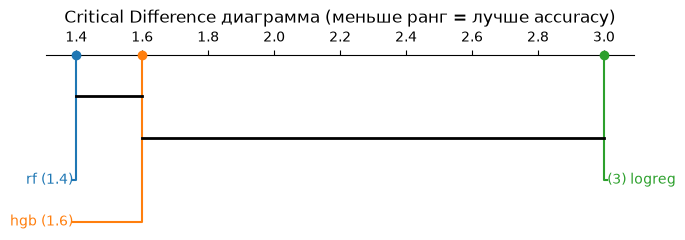

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 2.5))
sp.critical_difference_diagram(avg_ranks, nemenyi_results, ax=ax)
plt.title("Critical Difference диаграмма (меньше ранг = лучше accuracy)")
plt.tight_layout()
plt.show()

**Как читать диаграмму критических различий.** По горизонтали — средний ранг (чем меньше, тем лучше по точности). Модели, соединённые горизонтальной перемычкой, статистически неразличимы.

**Результат.** Критерий Фридмана: статистика 7.6, p = 0.022 — различия между моделями есть. Средние ранги: `rf` 1.4, `hgb` 1.6, `logreg` 3.0. По Неменьи значимо различаются только `logreg` и `rf` (p = 0.031); `logreg` против `hgb` — p = 0.069 (не дотягивает до 0.05), `rf` против `hgb` — p = 0.946. Устойчиво установить можно одно: RF лучше логистической регрессии. Про HGB против LogReg определённого вывода нет, хотя по рангам HGB почти так же хорош, как RF — при пяти датасетах мощность теста мала.

## Шаг 4 — Поправка Холма на множественные сравнения

В Шаге 2 получено 16 p-value (4 пары × 4 теста). Если к каждому применять порог 0.05 отдельно, то даже без реальных различий в среднем 16 × 0.05 = 0.8 проверки дадут ложный «значимый» результат. Метод Холма (шаговая процедура Бонферрони) пересчитывает p-value так, чтобы вероятность хотя бы одной ложной находки среди всех проверок не превышала 0.05.

In [19]:
p_values_list = (
    repeat_table["p_naive"].tolist()
    + repeat_table["p_corrected"].tolist()
    + repeat_table["p_5x2cv"].tolist()
    + repeat_table["p_mcnemar"].tolist()
)
reject, p_corrected_holm, _, _ = multipletests(p_values_list, alpha=0.05, method="holm")

holm_table = pd.DataFrame({
    "p_raw": p_values_list,
    "p_holm": p_corrected_holm,
    "reject_at_0.05": reject,
})
holm_table.round(4)

,p_raw,p_holm,reject_at_0.05
0,0.0187,0.2435,False
1,0.0017,0.0262,True
2,0.0156,0.2187,False
3,0.0694,0.6247,False
4,0.0433,0.4768,False
5,0.0011,0.0168,True
6,0.9221,1.0000,False
7,0.2968,1.0000,False
8,0.0366,0.4396,False
9,0.2042,1.0000,False


**Интерпретация.** До поправки значимыми (p < 0.05) были 7 из 16 результатов. После поправки значимыми остались 2: `hgb vs logreg` на `digits` по наивному (0.0017 → 0.026) и по corrected (0.0011 → 0.017) тестам. Остальные «находки» (например, наивный `rf vs logreg` на `digits`: 0.019 → 0.24, наивный `rf vs hgb` на `credit_g`: 0.016 → 0.22) поправки не выдерживают. Выжили результаты, у которых p было малым с самого начала.

## Графики

Три графика для сводки результатов: сравнение p-value по тестам, доверительные интервалы для разницы точности и тепловая карта средней точности.

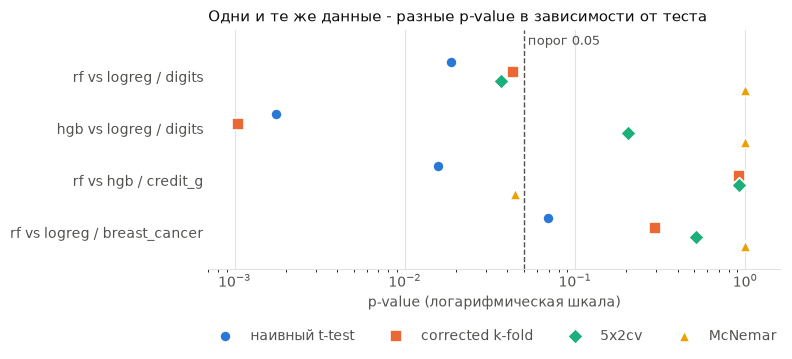

In [20]:
import matplotlib.pyplot as plt

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e3e2de"
tests = [
    ("p_naive",     "наивный t-test",   "#2a78d6", "o"),
    ("p_corrected", "corrected k-fold", "#eb6834", "s"),
    ("p_5x2cv",     "5x2cv",            "#1baf7a", "D"),
    ("p_mcnemar",   "McNemar",          "#eda100", "^"),
]

labels = (repeat_table["pair"] + " / " + repeat_table["dataset"]).tolist()
ypos = list(range(len(labels)))[::-1]
offsets = [0.27, 0.09, -0.09, -0.27]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.set_xscale("log")
ax.axvline(0.05, color=INK2, linewidth=1, linestyle="--", zorder=1)
ax.text(0.05, len(labels) - 0.45, " порог 0.05", color=INK2, fontsize=9, va="bottom")

for (col, name, color, marker), dy in zip(tests, offsets):
    ax.scatter(repeat_table[col], [y + dy for y in ypos], s=64, color=color,
               marker=marker, edgecolors="white", linewidths=1.2, label=name, zorder=3)

ax.set_yticks(ypos)
ax.set_yticklabels(labels, color=INK)
ax.set_xlabel("p-value (логарифмическая шкала)", color=INK2)
ax.set_xlim(0.0007, 1.6)
ax.set_ylim(-0.7, len(labels) - 0.1)
ax.tick_params(colors=INK2, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_title("Одни и те же данные - разные p-value в зависимости от теста",
             color=INK, loc="left", fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False, labelcolor=INK2)
fig.tight_layout()
fig.savefig("results/pvalues_by_test.png", dpi=150)
plt.show()


**Как читать.** Строка — пара моделей на датасете, точки — p-value четырёх тестов (логарифмическая шкала), пунктир — порог 0.05; левее пунктира тест называет разницу значимой. Строка `rf vs hgb / credit_g`: наивный тест левее порога, corrected и 5×2cv почти у 1.0 — тесты приходят к противоположным выводам. Строка `hgb vs logreg / digits` показывает исключение: corrected ещё левее наивного, а 5×2cv правее порога.

**Тепловая карта** средней точности: цвет считается внутри строки (чем темнее, тем лучше модель на этом датасете), числа в клетках — сами значения. Цвет показывает только порядок моделей в строке, а не величину разрыва.

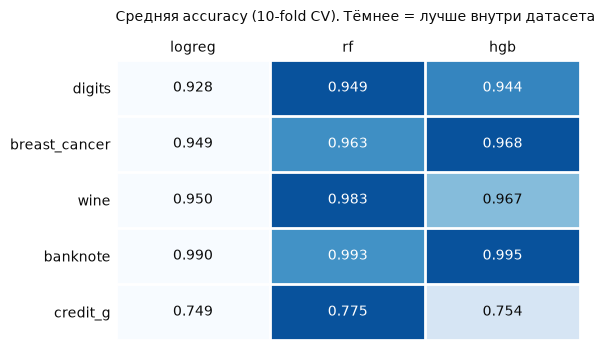

In [21]:
INK = "#0b0b0b"

# цвет считается внутри каждой строки: у credit_g accuracy около 0.75, у banknote около 0.99,
# при общей шкале различия моделей внутри строки были бы не видны
row_scaled = summary.sub(summary.min(axis=1), axis=0).div(
    summary.max(axis=1) - summary.min(axis=1), axis=0
)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.imshow(row_scaled.values, cmap="Blues", vmin=0, vmax=1.15, aspect="auto")

for i in range(summary.shape[0]):
    for j in range(summary.shape[1]):
        dark = row_scaled.iloc[i, j] > 0.6
        ax.text(j, i, f"{summary.iloc[i, j]:.3f}", ha="center", va="center",
                color="white" if dark else INK, fontsize=10)

ax.set_xticks(range(summary.shape[1]))
ax.set_xticklabels(summary.columns, color=INK)
ax.set_yticks(range(summary.shape[0]))
ax.set_yticklabels(summary.index, color=INK)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_xticks(np.arange(-.5, summary.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, summary.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", length=0)
ax.set_title("Средняя accuracy (10-fold CV). Тёмнее = лучше внутри датасета",
             color=INK, loc="left", fontsize=10, pad=28)
fig.tight_layout()
fig.savefig("results/summary_heatmap.png", dpi=150)
plt.show()


### Доверительные интервалы для разницы точности

p-value отвечает на вопрос «значимо или нет», но не говорит о размере разницы. Доверительный интервал показывает и то и другое: точка — средняя разность точности по 10 фолдам, отрезок — 95% интервал `mean ± t(0.975; 9) · SE`. Синий интервал — с наивной стандартной ошибкой `std/√k`, оранжевый — с поправкой Nadeau & Bengio `std · √(1/k + 1/(k−1))`. Если интервал накрывает 0, данные совместимы с отсутствием разницы.

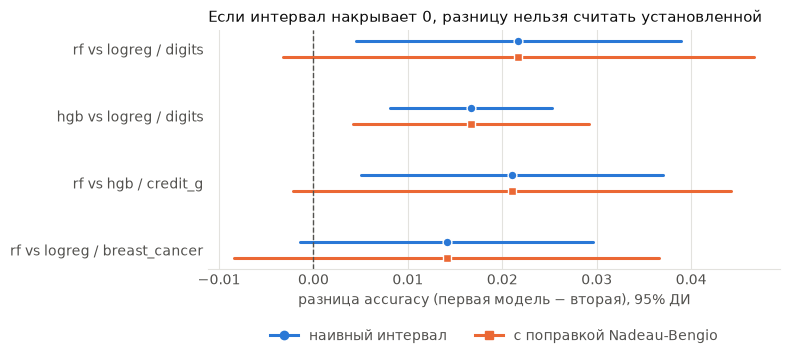

,label,mean,lo_n,hi_n,lo_c,hi_c
0,rf vs logreg / digits,0.0217,0.0045,0.0389,-0.0032,0.0467
1,hgb vs logreg / digits,0.0167,0.0081,0.0253,0.0042,0.0292
2,rf vs hgb / credit_g,0.0210,0.0050,0.0370,-0.0022,0.0442
3,rf vs logreg / breast_cancer,0.0141,-0.0014,0.0296,-0.0084,0.0366


In [22]:
from matplotlib.lines import Line2D

k = 10
rows = []
for ds, a, b in pairs_to_check:
    d = results[ds][a] - results[ds][b]
    mean, sd = d.mean(), d.std(ddof=1)
    tcrit = stats.t.ppf(0.975, k - 1)
    se_naive = sd / np.sqrt(k)
    se_corr = sd * np.sqrt(1 / k + 1 / (k - 1))
    rows.append({
        "label": f"{a} vs {b} / {ds}", "mean": mean,
        "lo_n": mean - tcrit * se_naive, "hi_n": mean + tcrit * se_naive,
        "lo_c": mean - tcrit * se_corr,  "hi_c": mean + tcrit * se_corr,
    })
ci = pd.DataFrame(rows)

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e3e2de"
fig, ax = plt.subplots(figsize=(8, 3.8))
ypos = list(range(len(ci)))[::-1]
for y, (_, r) in zip(ypos, ci.iterrows()):
    ax.plot([r.lo_n, r.hi_n], [y + 0.12] * 2, color="#2a78d6", linewidth=2.2, solid_capstyle="round")
    ax.plot([r.lo_c, r.hi_c], [y - 0.12] * 2, color="#eb6834", linewidth=2.2, solid_capstyle="round")
    ax.scatter([r["mean"]], [y + 0.12], color="#2a78d6", s=40, edgecolors="white", linewidths=1, zorder=3)
    ax.scatter([r["mean"]], [y - 0.12], color="#eb6834", s=40, marker="s", edgecolors="white", linewidths=1, zorder=3)

ax.axvline(0, color=INK2, linewidth=1, linestyle="--")
ax.set_yticks(ypos)
ax.set_yticklabels(ci["label"], color=INK)
ax.set_xlabel("разница accuracy (первая модель − вторая), 95% ДИ", color=INK2)
ax.tick_params(colors=INK2, length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_title("Если интервал накрывает 0, разницу нельзя считать установленной",
             color=INK, loc="left", fontsize=11)
ax.legend(handles=[
    Line2D([0], [0], color="#2a78d6", lw=2.2, marker="o", label="наивный интервал"),
    Line2D([0], [0], color="#eb6834", lw=2.2, marker="s", label="с поправкой Nadeau-Bengio"),
], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, labelcolor=INK2)
fig.tight_layout()
fig.savefig("results/confidence_intervals.png", dpi=150)
plt.show()
ci.round(4)

**Результат.** Наивные интервалы не накрывают 0 у трёх пар из четырёх, интервалы с поправкой — только у `hgb vs logreg` на `digits`. Размеры разницы малы: 1.4–2.2 процентных пункта. Оговорка: поправка здесь применена к фолдам `cross_val_score`, а `mlxtend` в Шаге 2 использует другое разбиение, поэтому на пограничном случае (`rf vs logreg` на `digits`: нижняя граница интервала −0.003, при этом `p_corr = 0.043` в `mlxtend`) выводы формально расходятся; это граница порога, а не противоречие.

## Шаг 5 — Симуляция: насколько на самом деле ошибается каждый тест

Таблицы выше не отвечают на вопрос, какой тест «прав»: истинной разницы между реальными моделями мы не знаем. Поэтому ставим контролируемый эксперимент с известным ответом.

**Данные.** Каждый раз генерируется новый набор из 200 объектов с двумя классами; у каждого объекта два независимых «вида» по 5 признаков (класс сдвигает среднее признака на ±shift, остальное — шум). Модель A (логистическая регрессия) видит только первый вид, модель B — только второй.
- **Сценарий H0:** сдвиг одинаков (0.45) в обоих видах, по симметрии ожидаемая точность моделей **одинакова**, H0 верна. Доля случаев, когда тест на уровне 0.05 всё же говорит «значимо», — это **ошибка первого рода** (должна быть около 5%).
- **Сценарий H1:** во втором виде сдвиг меньше (0.30), модель B объективно хуже. Доля «значимых» результатов — это **мощность** теста.

**Пять процедур:** наивный t-test на 10-fold; он же с поправкой Nadeau & Bengio; 5×2cv; наивный t-test на 30 повторных случайных разбиениях (2/3 обучение, 1/3 проверка); он же с поправкой (`1/30 + 1/2`). Повторные случайные разбиения — именно тот сценарий, для которого Nadeau & Bengio придумали поправку, поэтому он добавлен к основной схеме проекта.

Каждый сценарий — 500 независимых повторов (стандартная ошибка оценки доли около 1–2 п.п.).

In [23]:
import warnings
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedKFold, ShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")

D = 5             # признаков в каждом "виде"
N_OBJECTS = 200
N_REPS = 500
K, J = 10, 30     # число фолдов и число повторных разбиений
METHODS = ["наивный, 10-fold", "corrected, 10-fold", "5x2cv",
           "наивный, 30 разбиений", "corrected, 30 разбиений"]


def make_two_view_data(rng, shift1, shift2):
    y = rng.randint(0, 2, N_OBJECTS)
    sign = (2 * y - 1)[:, None]
    view1 = sign * shift1 + rng.randn(N_OBJECTS, D)
    view2 = sign * shift2 + rng.randn(N_OBJECTS, D)
    return np.hstack([view1, view2]), y


def p_from_differences(d, variance_factor, df):
    sd = d.std(ddof=1)
    if sd == 0:
        return np.nan
    t = d.mean() / (sd * np.sqrt(variance_factor))
    return 2 * stats.t.sf(abs(t), df)


def one_repetition(rep, shift2):
    rng = np.random.RandomState(rep)
    X, y = make_two_view_data(rng, 0.45, shift2)
    make_model = lambda cols: make_pipeline(
        ColumnTransformer([("select", "passthrough", cols)]), LogisticRegression())
    model_a, model_b = make_model(list(range(D))), make_model(list(range(D, 2 * D)))

    cv = StratifiedKFold(n_splits=K, shuffle=True, random_state=rep)
    d = cross_val_score(model_a, X, y, cv=cv) - cross_val_score(model_b, X, y, cv=cv)
    p_naive_kfold = p_from_differences(d, 1 / K, K - 1)
    p_corr_kfold = p_from_differences(d, 1 / K + 1 / (K - 1), K - 1)
    _, p_5x2 = paired_ttest_5x2cv(model_a, model_b, X, y, random_seed=rep)

    resampling = ShuffleSplit(n_splits=J, test_size=1 / 3, random_state=rep)
    d2 = cross_val_score(model_a, X, y, cv=resampling) - cross_val_score(model_b, X, y, cv=resampling)
    p_naive_res = p_from_differences(d2, 1 / J, J - 1)
    p_corr_res = p_from_differences(d2, 1 / J + 1 / 2, J - 1)   # n_test / n_train = (1/3) / (2/3) = 1/2
    return [p_naive_kfold, p_corr_kfold, p_5x2, p_naive_res, p_corr_res]


sim_rates = {}
for scenario, shift2 in [("H0: модели равны", 0.45), ("H1: модель B хуже", 0.30)]:
    p_array = np.array(Parallel(n_jobs=-1)(delayed(one_repetition)(r, shift2) for r in range(N_REPS)))
    p_array = p_array[~np.isnan(p_array).any(axis=1)]
    sim_rates[scenario] = (p_array < 0.05).mean(axis=0)

sim_table = pd.DataFrame(sim_rates, index=METHODS)
sim_table.round(3)

,H0: модели равны,H1: модель B хуже
"наивный, 10-fold",0.030,0.534
"corrected, 10-fold",0.008,0.254
5x2cv,0.040,0.372
"наивный, 30 разбиений",0.588,0.974
"corrected, 30 разбиений",0.038,0.570


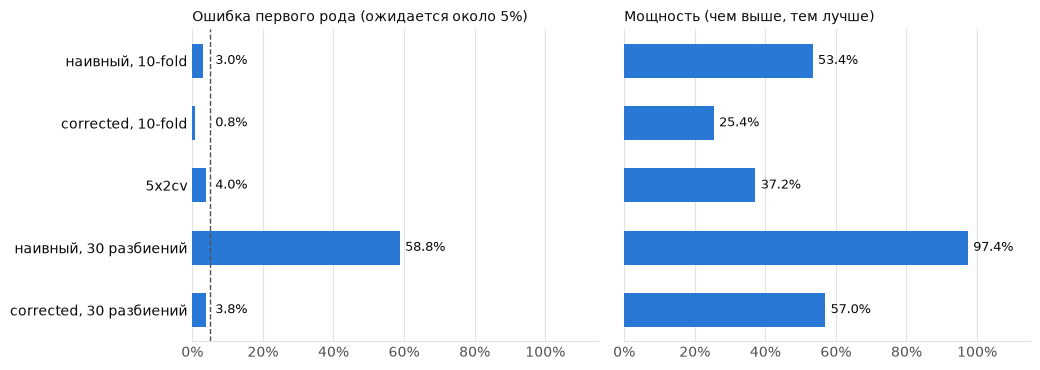

In [24]:
from matplotlib.ticker import PercentFormatter

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e3e2de"
panels = [("H0: модели равны", "Ошибка первого рода (ожидается около 5%)"),
          ("H1: модель B хуже", "Мощность (чем выше, тем лучше)")]
ypos = np.arange(len(METHODS))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, (scenario, title) in zip(axes, panels):
    values = sim_table[scenario].values
    ax.barh(ypos, values, height=0.55, color="#2a78d6")
    for y_, v in zip(ypos, values):
        ax.text(max(v, 0.05) + 0.015, y_, f"{v:.1%}", va="center", color=INK, fontsize=9)
    ax.set_xlim(0, 1.15)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(title, color=INK, loc="left", fontsize=10)
    ax.tick_params(colors=INK2, length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

axes[0].axvline(0.05, color=INK2, linewidth=1, linestyle="--")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(METHODS, color=INK)
fig.tight_layout()
fig.savefig("results/simulation_size_power.png", dpi=150)
plt.show()

**Результаты симуляции** (500 повторов на сценарий):

| процедура | ошибка 1-го рода (H0) | мощность (H1) |
|---|---|---|
| наивный, 10-fold | 3.0% | 53.4% |
| corrected, 10-fold | 0.8% | 25.4% |
| 5×2cv | 4.0% | 37.2% |
| наивный, 30 разбиений | **58.8%** | 97.4% |
| corrected, 30 разбиений | 3.8% | 57.0% |

**Что это значит.**
1. Катастрофически неверен наивный t-test на **повторных случайных разбиениях**: он «находит» разницу между заведомо равными моделями в 59% случаев вместо 5%. Здесь пересечение обучающих выборок максимально, допущение независимости разрушено полностью. Поправка Nadeau & Bengio возвращает ошибку к номиналу (3.8%).
2. Наивный t-test на **10-fold** в этом дизайне ошибку первого рода **не завышает** (3.0%). Утверждение «наивный тест на фолдах всегда слишком оптимистичен» на этих данных не подтвердилось: допущение независимости формально нарушено, но практический эффект зависит от схемы разбиения и данных.
3. Поправка Nadeau & Bengio, применённая к 10-fold, **излишне консервативна**: ошибка 0.8% (ниже номинала), мощность падает с 53% до 25%. Поэтому большие p-value у corrected теста на реальных данных отчасти объясняются потерей мощности, а не только «исправлением» наивного.
4. 5×2cv держит ошибку на уровне номинала (4.0%) при умеренной мощности (37%) — более сбалансированная альтернатива для k-fold схемы.

**Ограничение:** это один дизайн (логистическая регрессия, 200 объектов, гауссовы признаки); количественные значения на других моделях и данных будут иными. Качественная картина (поправка нужна прежде всего для повторных разбиений; для k-fold она консервативна) согласуется с выводами Dietterich (1998).

## Выводы

1. **Расхождение тестов на реальных данных.** На одной и той же паре наивный и корректные тесты могут приводить к противоположным выводам: `rf vs hgb` на `credit_g` — наивный p = 0.016, corrected и 5×2cv p ≈ 0.92 (разница точности 2 п.п.). Но зависимость не монотонна: на `hgb vs logreg` на `digits` corrected p (0.0011) меньше наивного (0.0017), а 5×2cv (0.20) не значим.
2. **Симуляция показала, где именно проблема.** Наивный t-test на повторных случайных разбиениях ошибается в 59% случаев при номинальных 5%; на 10-fold он близок к номиналу (3%). Поправка Nadeau & Bengio исправляет повторные разбиения (3.8%), но на 10-fold излишне консервативна (0.8%, мощность 25% против 53%). Тезис «наивный t-test на фолдах CV некорректен» верен как утверждение о нарушенных допущениях, но его практическая тяжесть зависит от схемы разбиения.
3. **Групповое сравнение.** Критерий Фридмана значим (p = 0.022); по Неменьи устойчиво отличается только `logreg` от `rf` (p = 0.031), `rf` и `hgb` неразличимы (p = 0.946).
4. **Множественные сравнения.** После поправки Холма из 7 «значимых» результатов из 16 осталось 2 (обе — `hgb vs logreg` на `digits`).
5. **Размер эффекта.** Разницы между моделями малы (1.4–2.2 п.п.); доверительные интервалы с поправкой для трёх пар из четырёх накрывают 0.

## Ограничения

- Пять датасетов — минимум для критерия Фридмана и Неменьи, мощность мала (отсюда `logreg` против `hgb`: p = 0.069 при рангах 3.0 и 1.6).
- Гиперпараметры по умолчанию, без тюнинга; `LogisticRegression` на нестандартизованных признаках не сошлась за 1000 итераций (`ConvergenceWarning`).
- McNemar считается на одном разбиении (`random_state=42`), 5×2cv — при одном `random_seed`; на других разбиениях числа изменятся.
- `paired_ttest_kfold_cv` (`mlxtend`) использует `KFold`, а `cross_val_score` — стратифицированное разбиение, поэтому наивный и corrected p-value в Шаге 2 посчитаны на разных разбиениях.
- Кодирование `credit_g` (one-hot) выполнено один раз на всех данных до кросс-валидации; для one-hot это не использует информацию о метках, но формально предобработка стоит вне фолдов.
- Симуляция — один дизайн (логистическая регрессия, 200 объектов, гауссовы признаки, 500 повторов); количественные значения на других моделях будут иными.